In [1]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
yapwh1208_supermarket_sales_data_path = kagglehub.dataset_download('yapwh1208/supermarket-sales-data')

print('Data source import complete.')


100%|██████████| 8.47M/8.47M [00:00<00:00, 78.4MB/s]

Extracting files...


Data source import complete.


In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt  # Data visualization library
import seaborn as sns  # Data visualization library for creating informative and attractive statistical graphics

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [4]:
# Query Cell: Data Import from Multiple Files

# Summary:
# In this query cell, four datasets—'veg_category_df,' 'veg_txn_df,' 'veg_whsle_df,' and 'loss_rate_df'—are imported from separate CSV files.
# These datasets contain information related to supermarket sales and associated data, which will be used for further analysis and exploratory data analysis (EDA) tasks.
# Importing these datasets is the initial step in preparing the data for analysis, and they will be explored, cleaned, and examined in subsequent steps to extract insights and make data-driven decisions.

veg_category_df = pd.read_csv(r'annex1.csv')
veg_txn_df = pd.read_csv(r'annex2.csv')
veg_whsle_df = pd.read_csv(r'annex3.csv')
loss_rate_df = pd.read_csv(r'annex4.csv')

In [5]:
# Activity 1: Inspect the first few rows of a dataframe called `veg_whsle_df` to gain an overview of its columns and values.
veg_whsle_df.head()

# Activity 2: Inspect Data Types and Column Names
veg_whsle_df.dtypes

# Activity 3: Data Type Enhancement: Convert the data type of the 'Date' column in 'veg_whsle_df' from 'Object' to 'Date'.
veg_whsle_df['Date'] = pd.to_datetime(veg_whsle_df['Date'])

# Activity 4: Date Simplification: Truncate the 'Date' column to retain only the date component without the time information.
veg_whsle_df['Date'] = veg_whsle_df['Date'].dt.floor('D')

# Activity 5: Define New Column Names
new_column_names = ['whsle_date', 'item_code', 'whsle_px_rmb-kg']

# Activity 6: Apply Column Name Changes
veg_whsle_df.rename(columns=dict(zip(veg_whsle_df.columns, new_column_names)), inplace=True)


In [6]:
# Import SQLAlchemy and Create a SQLite Engine
# import sqlalchemy and create a sqlite engine
from sqlalchemy import create_engine
from sqlalchemy import text
engine = create_engine('sqlite://', echo=False)
con=engine.connect()

# Store DataFrames in SQLite Tables
veg_whsle_df.to_sql("veg_whsle_df", con=engine)

55982

In [7]:
# SQL Query 1: Define Query and visualize the initial rows and columns 'Wholesale dataset'
query =text(
'''

select *
from veg_whsle_df

'''

)

df_sql = pd.read_sql_query(query,con)

df_sql.head()

,index,whsle_date,item_code,whsle_px_rmb-kg
0,0,2020-07-01 00:00:00.000000,102900005115762,3.88
1,1,2020-07-01 00:00:00.000000,102900005115779,6.72
2,2,2020-07-01 00:00:00.000000,102900005115786,3.19
3,3,2020-07-01 00:00:00.000000,102900005115793,9.24
4,4,2020-07-01 00:00:00.000000,102900005115823,7.03


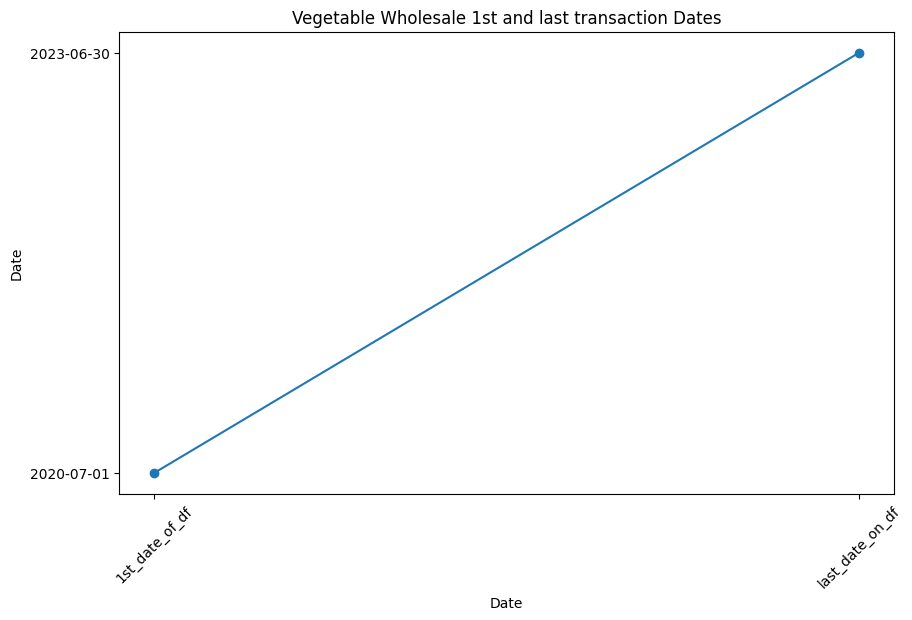

In [8]:
# SQL Query 2: Define SQL Query to Find the First and Last Transaction Dates

query =text(
'''

select min(STRFTIME('%Y-%m-%d',[whsle_date])) as '1st_date_of_df', max(STRFTIME('%Y-%m-%d',[whsle_date])) as 'last_date_on_df'
from veg_whsle_df

'''

)

df_sql = pd.read_sql_query(query,con)

# Create a line plot
plt.figure(figsize=(10, 6))
plt.plot(df_sql.columns, df_sql.values.flatten(), marker='o')
plt.title('Vegetable Wholesale 1st and last transaction Dates')
plt.xlabel('Date')
plt.ylabel('Date')
plt.xticks(rotation=45)
plt.show()

In [9]:
# SQL Query 3: Define query for Wholesale Transactions dataset Analysis
query = text('''
SELECT STRFTIME('%Y-%m-%d', [whsle_date]) AS 'wholesale_date', item_code, [whsle_px_rmb-kg]
FROM veg_whsle_df
''')

# Execute the SQL Query and Fetch Results into a DataFrame
df_sql = pd.read_sql_query(query, con)

# Display the First Few Rows of Wholesale Transaction Data
df_sql.head()

,wholesale_date,item_code,whsle_px_rmb-kg
0,2020-07-01,102900005115762,3.88
1,2020-07-01,102900005115779,6.72
2,2020-07-01,102900005115786,3.19
3,2020-07-01,102900005115793,9.24
4,2020-07-01,102900005115823,7.03


In [10]:
# SQL Query 4: Define SQL Query to Find the Highest Wholesale Price
query = text('''
SELECT max([whsle_px_rmb-kg]) AS max_whsle_price
FROM veg_whsle_df
''')

# Execute the SQL Query and Retrieve Results into a DataFrame
df_sql = pd.read_sql_query(query, con)

# Display the Maximum Wholesale Price
df_sql.head()


,max_whsle_price
0,141.0


In [11]:
# SQL Query 5: Define SQL Query to Find the Lowest Wholesale Price
query = text('''
SELECT min([whsle_px_rmb-kg])
FROM veg_whsle_df
''')

# Execute the SQL Query and Retrieve the Results into a DataFrame
df_sql = pd.read_sql_query(query, con)

# Display the Minimum Wholesale Price
df_sql.head()


,min([whsle_px_rmb-kg])
0,0.01


In [12]:
# SQL Query 6: Define SQL Query to Calculate the Average Wholesale Price
query = text('''
SELECT avg([whsle_px_rmb-kg])
FROM veg_whsle_df
''')

# Execute the SQL Query and Retrieve the Results into a DataFrame
df_sql = pd.read_sql_query(query, con)

# Display the Average Wholesale Price
df_sql.head()


,avg([whsle_px_rmb-kg])
0,5.96262


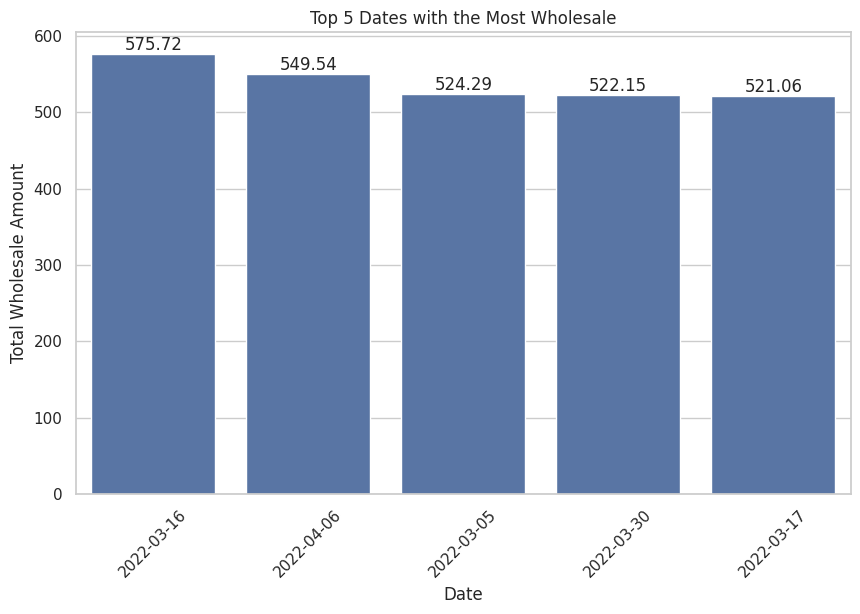

In [13]:
# SQL Query 7: Define SQL Query to Identify the Top 5 Dates with the Most Wholesale Sales

query =text(
'''

select STRFTIME('%Y-%m-%d',[whsle_date]) as [whsle_date], sum([whsle_px_rmb-kg]) as sum_by_date, count([whsle_px_rmb-kg]) num_of_sales
from veg_whsle_df
group by [whsle_date]
Order by sum([whsle_px_rmb-kg]) DESC
limit 5;


'''

)

df_sql = pd.read_sql_query(query,con)

# Create a bar chart using Seaborn
plt.figure(figsize=(10, 6))
sns.set(style="whitegrid")  # Set style
ax = sns.barplot(x='whsle_date', y='sum_by_date', data=df_sql)

# Add labels for the bars
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')

plt.title('Top 5 Dates with the Most Wholesale')
plt.xlabel('Date')
plt.ylabel('Total Wholesale Amount')
plt.xticks(rotation=45)

plt.show()


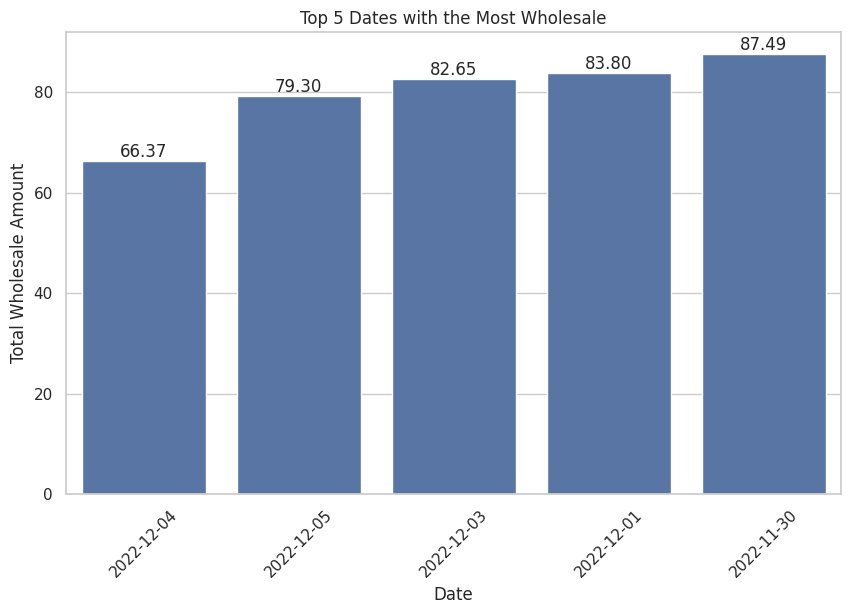

In [14]:
# SQL Query 8: Define SQL Query to Identify the Top 5 Dates with the least Wholesale Sales

query =text(
'''

select STRFTIME('%Y-%m-%d',[whsle_date]) as [whsle_date], sum([whsle_px_rmb-kg]) as sum_by_date, count([whsle_px_rmb-kg]) num_of_sales
from veg_whsle_df
group by [whsle_date]
Order by sum([whsle_px_rmb-kg]) ASC
limit 5;


'''

)

df_sql = pd.read_sql_query(query,con)

# Create a bar chart using Seaborn
plt.figure(figsize=(10, 6))
sns.set(style="whitegrid")  # Set style
ax = sns.barplot(x='whsle_date', y='sum_by_date', data=df_sql)

# Add labels for the bars
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')

plt.title('Top 5 Dates with the Most Wholesale')
plt.xlabel('Date')
plt.ylabel('Total Wholesale Amount')
plt.xticks(rotation=45)
plt.show()